Données réelles (https://archive.ics.uci.edu/dataset/320/student+performance) :
* proviennent de l'étude de Cortez & Silva (2008)
* ont été collectées en 2005-2006 dans deux lycées portugais, à travers des bulletins scolaires et des questionnaires

Nous travaillerons sur le jeu de données portugais.

# Importation des librairies

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Importation du jeu de données

On utilise `encoding="utf-8-sig"` pour retirer le BOM (*Byte Order Mark*) devant le nom des colonnes.

In [20]:
%load_ext autoreload
%autoreload 2
import outils as ot
df = ot.load_data()
df.info()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  ac

# Exploration du jeu de données

Le DataFrame contient 649 lignes et 33 colonnes.

In [18]:
df.describe().round(2)

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00,649.00
mean,16.74,2.51,2.31,1.57,1.93,0.22,3.93,3.18,3.18,1.50,2.28,3.54,3.66,11.40,11.57,11.91
std,1.22,1.13,1.10,0.75,0.83,0.59,0.96,1.05,1.18,0.92,1.28,1.45,4.64,2.75,2.91,3.23
min,15.00,0.00,0.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,0.00,0.00,0.00
25%,16.00,2.00,1.00,1.00,1.00,0.00,4.00,3.00,2.00,1.00,1.00,2.00,0.00,10.00,10.00,10.00
50%,17.00,2.00,2.00,1.00,2.00,0.00,4.00,3.00,3.00,1.00,2.00,4.00,2.00,11.00,11.00,12.00
75%,18.00,4.00,3.00,2.00,2.00,0.00,5.00,4.00,4.00,2.00,3.00,5.00,6.00,13.00,13.00,14.00
max,22.00,4.00,4.00,4.00,4.00,3.00,5.00,5.00,5.00,5.00,5.00,5.00,32.00,19.00,19.00,19.00


Pour chacune des colonnes numériques, il n'y a aucune valeur manquante : `count` = 649 à chaque fois.

`G3` est notre cible à prédire.

Nous remarquons également que `G1`, `G2` et `G3` sont très proches. Si la corrélation s'avère être réellement très élevée, il peut être pertinent de retirer `G1` et `G2` des modèles afin qu'ils soient plus informatifs.

Une moyenne de 0 semble suspecte, regardons combien d'élèves cela concerne.

In [19]:
df[df.G3 == 0]

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
163,GP,M,18,U,LE3,T,1,1,other,other,...,2,3,5,2,5,4,0,11,9,0
440,MS,M,16,U,GT3,T,1,1,at_home,services,...,5,4,5,4,5,3,0,7,0,0
519,MS,M,16,R,GT3,T,2,1,other,services,...,5,2,1,1,1,2,0,8,7,0
563,MS,M,17,U,GT3,T,2,2,other,other,...,1,2,1,2,3,5,0,7,0,0
567,MS,M,18,R,GT3,T,3,2,services,other,...,2,3,1,2,2,5,0,4,0,0
583,MS,F,18,R,GT3,T,2,2,other,other,...,5,5,5,1,1,3,0,8,6,0
586,MS,F,17,U,GT3,T,4,2,teacher,services,...,5,5,5,1,3,5,0,8,8,0
597,MS,F,18,R,GT3,T,2,2,at_home,other,...,4,3,3,1,1,4,0,9,0,0
603,MS,F,18,R,LE3,A,4,2,teacher,other,...,5,3,1,1,1,5,0,5,0,0
605,MS,F,19,U,GT3,T,1,1,at_home,services,...,5,5,5,2,3,2,0,5,0,0


15 élèves ont donc une note pour `G3` nulle. Et pourtant, ils n'ont aucune absence. Peut-être que lorsqu'un.e élève quitte l'établissement, ce n'est pas pris en compte dans les absences.

Regardons la distribution de `G3`.

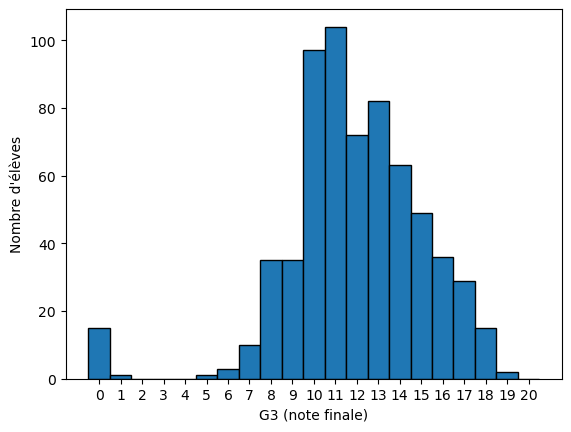

In [21]:
plt.hist(df["G3"], bins=np.arange(-0.5, 21, 1), edgecolor="black")
plt.xlabel("G3 (note finale)")
plt.ylabel("Nombre d'élèves")
plt.xticks(range(0, 21))
plt.show()

Nous remarquons à droite une distribution proche d'une loi normale, en cloche. Le pic se situant entre 10 et 12.

Les élèves qui ont 0 et 1 semblent à part. Nous pourrions être tentés de les exclure mais cela fausserait le modèle car nous ignorerions toute une frange d'élèves en difficulté. 

Regardons la distribution de toutes les variables.

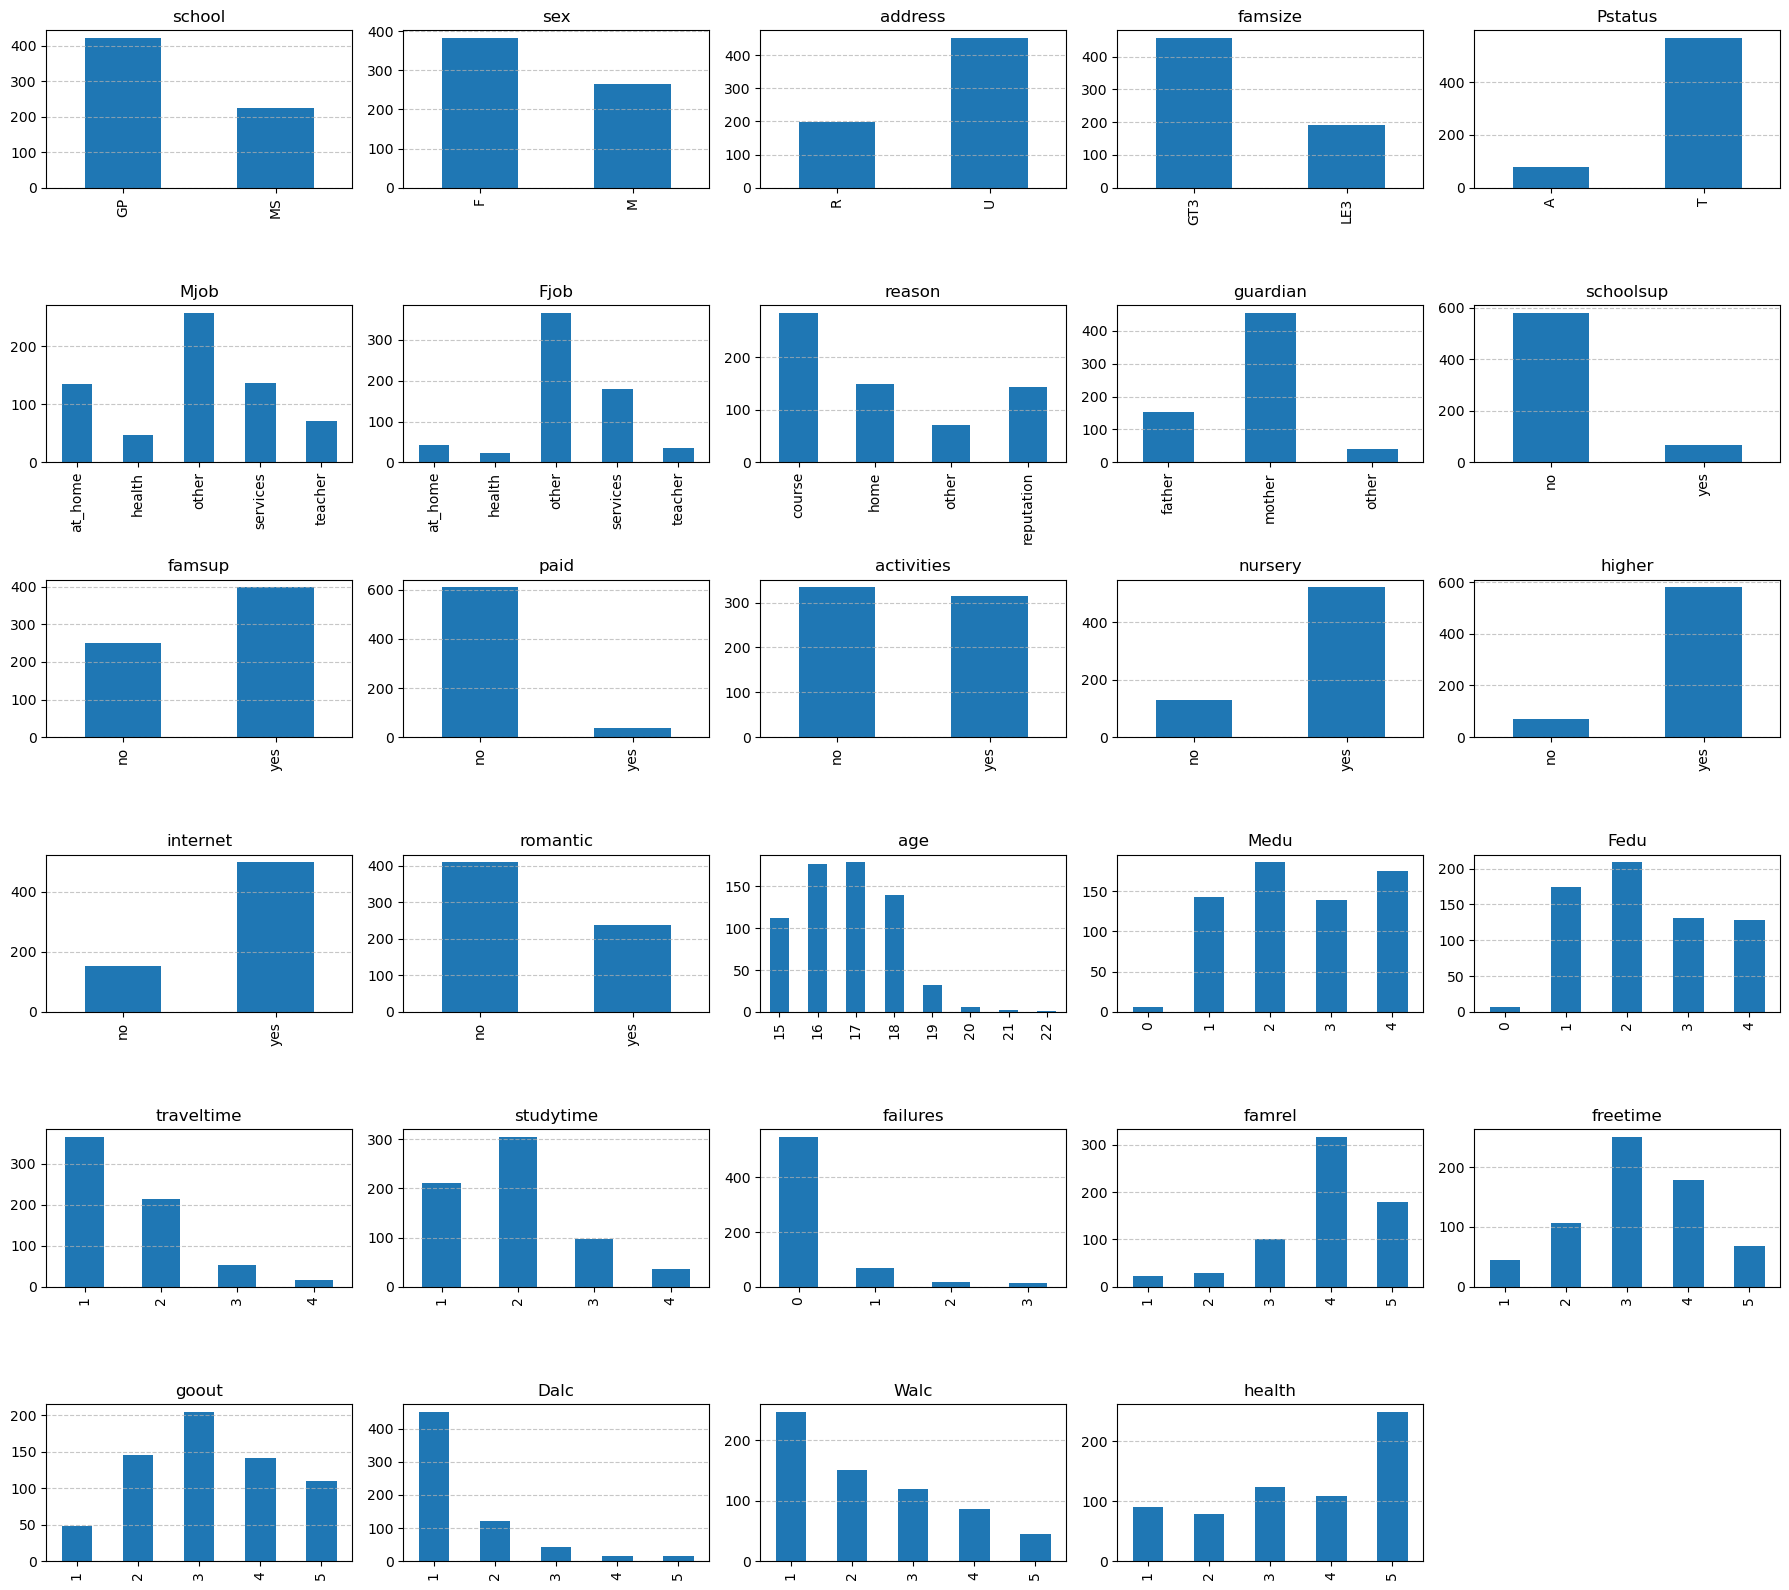

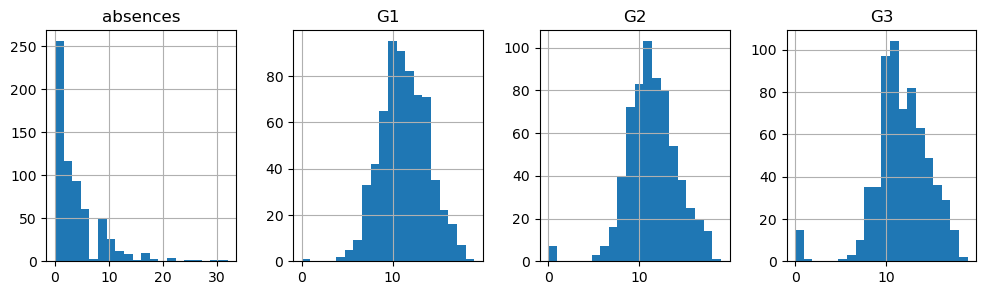

In [ ]:
cols = ot.CATEGORICAL + [c for c in ot.NUMERIC if c != "absences"]
fig, axes = plt.subplots(6, 5, figsize=(18, 16))
for ax, c in zip(axes.ravel(), cols): #.ravel() permet d'applatir la grille pour un parcours plus simple
    df[c].value_counts().sort_index().plot.bar(ax=ax, title=c)
    ax.set_xlabel("")
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
for ax in axes.ravel()[len(cols):]:
    ax.axis("off")                    # n'affiche pas les cases vides 
plt.tight_layout()
plt.show()

# nous traitons ces variables à part car elles ont beaucoup de valeurs distinctes
df[["absences", "G1", "G2", "G3"]].hist(bins=20, figsize=(12, 3), layout=(1, 4))
plt.show()

Nous remarquons que certaines classes sont très déséquilibrées. Par exemple : `paid` et `higher`, contrairement à `activities`. Si les modalités sont très **rares**, les modèles auront peu d'exemples pour en apprendre l'effet : elles sont **peu informatives**, sauf si la minorité est fortement reliée à `G3`.

La distribution des `absences` est asymétrique : la plupart des élèves ont très peu d'absences, et une minorité d'élèves ont un nombre d'absences conséquent. 

Les variables `G1`, `G2` et `G3` ont des distributions similaires : en cloche avec des zéros isolés.